M# Proyecto 2 — Diseño generativo de personajes: *Glimmerfen*

**Curso:** Deep Learning 2026, Universidad del Valle · **Docente:** Kevin Recinos
**Pareja:** Cindy Gualim y Gadiel Ocaña

Este notebook es el recorrido ejecutable completo del proyecto: define el
universo, prepara los datos, entrena la GAN base y las dos variantes
experimentales (pérdida y estabilización), muestra las tres evidencias
obligatorias, construye la galería final de 10 personajes y cierra con la
reflexión pedida en el enunciado.

El informe narrativo completo (con el mismo contenido en formato de texto)
está en `../PROJECT.md`. El código reutilizable vive en `../src/ganverse/`
y está cubierto por pruebas unitarias en `../tests/` (`pytest`).

In [1]:
import sys, os
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO_ROOT / "src"))

import torch
import matplotlib.pyplot as plt
import numpy as np

from ganverse.dataset import save_dataset, GlimmerfenDataset, ELEMENT_NAMES
from ganverse.models import Generator, Discriminator
from ganverse.train import PRESETS, train, get_or_create_fixed_noise
from ganverse import evidence as ev
from ganverse import gallery as gl
from ganverse.utils import get_device, set_seed, save_image_grid, tensor_to_uint8, load_json

# Si RETRAIN=False (recomendado), el notebook reutiliza los checkpoints ya
# entrenados en experiments/ (rápido de revisar). Si RETRAIN=True, reentrena
# las 3 configuraciones desde cero (~50 min en GPU Apple Silicon / mucho más en CPU).
RETRAIN = False

DATA_NPY = REPO_ROOT / "data" / "glimmerfen" / "glimmerfen_64x64.npy"
EXPERIMENTS_DIR = REPO_ROOT / "experiments"
FIGURES_DIR = REPO_ROOT / "figures"
GALERIA_DIR = REPO_ROOT / "galeria"

device = get_device()
print(f"Usando dispositivo: {device}")

Usando dispositivo: mps


## 1. Universo visual: *Glimmerfen*

*Glimmerfen* es un bosque brumoso habitado por pequeños **espíritus
guardianes elementales**: criaturas tipo "blob" con una panza de color más
claro, ojos grandes (a veces uno solo) y, opcionalmente, un apéndice
distintivo (cuernos, alas, orejas, cola o antena). Cada espíritu pertenece a
uno de **seis elementos** — fuego, agua, tierra, aire, luz, sombra — que fija
su paleta de color y mantiene un estilo visual consistente en toda la
galería.

**Rasgos que la galería final debe mostrar** (la vara con la que juzgamos
nuestro propio resultado, sección 2.1 del enunciado): silueta tipo
criatura/blob, paleta coherente con alguno de los seis elementos, ojos
grandes como rasgo central, fondo oscuro plano consistente, y variedad real
de siluetas/apéndices entre los 10 personajes finales.

## 2. Datos

El dataset se **genera proceduralmente por código** (`ganverse/dataset.py`,
dibujo vectorial con PIL + antialiasing por supersampling), no se descarga de
internet. Esto resuelve de raíz el requisito de documentar origen y licencia:
el equipo es autor y titular de cada imagen (CC0), y no hay rostros reales ni
personajes de terceros involucrados.

- **Tamaño:** 4000 imágenes, 64×64×3 (resolución recomendada en la sección 4).
- **Preparación:** normalización a `[-1, 1]`; aumento de datos por flip
  horizontal aleatorio (válido porque los espíritus son simétricos por diseño).
- **Consistencia de estilo:** fondo plano único y paleta restringida a 6
  familias de color, siguiendo la recomendación de preferir pocas imágenes
  con estilo consistente sobre un conjunto heterogéneo.

In [2]:
if not DATA_NPY.exists():
    print("Generando dataset procedural (semilla 42)...")
    save_dataset(n=4000, out_dir=DATA_NPY.parent, seed=42, n_png_samples=30)
else:
    print("Dataset ya existe, reutilizando:", DATA_NPY)

meta = load_json(DATA_NPY.parent / "metadata.json")
for k, v in meta.items():
    print(f"{k}: {v}")

Dataset ya existe, reutilizando: /Users/gadielocana/Documents/U/Semestre7/DeepLearning/Proyecto2/data/glimmerfen/glimmerfen_64x64.npy
n_images: 4000
resolution: 64
channels: 3
seed: 42
origin: Generado proceduralmente con PIL por el equipo (src/ganverse/dataset.py). No contiene rostros reales ni personajes de terceros.
license: CC0 / propiedad del equipo (Cindy Gualim y Gadiel Ocaña)
universe: Glimmerfen: espiritus guardianes elementales de bosque
elements: ['fuego', 'agua', 'tierra', 'aire', 'luz', 'sombra']


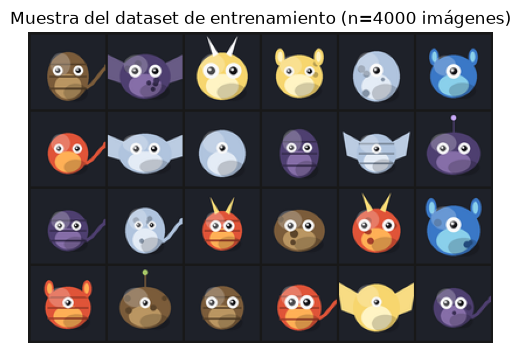

In [3]:
# Vista previa de 24 imágenes reales del dataset de entrenamiento
ds = GlimmerfenDataset(DATA_NPY, augment=False)
sample_idx = np.random.RandomState(0).choice(len(ds), 24, replace=False)
sample_batch = torch.stack([ds[i] for i in sample_idx])
save_image_grid(sample_batch, FIGURES_DIR / "dataset_sample_grid.png", nrow=6)

img = plt.imread(FIGURES_DIR / "dataset_sample_grid.png")
plt.figure(figsize=(6, 6)); plt.imshow(img); plt.axis("off")
plt.title(f"Muestra del dataset de entrenamiento (n={len(ds)} imágenes)")
plt.show()

## 3. Arquitectura de la GAN

Se usa una **DCGAN** (Radford et al., 2015) como arquitectura base: el
generador (`ganverse.models.Generator`) son 5 capas `ConvTranspose2d` con
`BatchNorm+ReLU` de `100×1×1` a `3×64×64` con salida `Tanh`. El discriminador
(`ganverse.models.Discriminator`) son 4 capas `Conv2d`+`LeakyReLU(0.2)` más
una capa final a un logit crudo, y admite 3 modos de normalización
intercambiables por configuración (`"batch"`, `"spectral"`, `"none"`), lo que
nos permite correr los tres experimentos reusando exactamente el mismo
código.

Se eligió DCGAN (en vez de, por ejemplo, Conditional GAN) porque el
enunciado recomienda "empezar simple" y porque no necesitamos condicionar la
generación a una etiqueta — la variedad de elementos/apéndices debe emerger
del espacio latente, no de una etiqueta explícita.

In [4]:
g_demo = Generator(latent_dim=100, feature_maps=64)
d_demo = Discriminator(feature_maps=64, normalization="batch")
n_params_g = sum(p.numel() for p in g_demo.parameters())
n_params_d = sum(p.numel() for p in d_demo.parameters())
print(f"Parámetros del Generador:     {n_params_g:,}")
print(f"Parámetros del Discriminador: {n_params_d:,}")
del g_demo, d_demo

Parámetros del Generador:     3,576,704
Parámetros del Discriminador: 2,765,569


## 4. Entrenamiento de la configuración base

Configuración base (`PRESETS["baseline"]`): DCGAN, pérdida BCE no saturante,
BatchNorm en D, Adam(lr=2e-4, betas=(0.5,0.999)), 45 épocas, batch 128,
semilla 2026. Esta es la configuración de referencia para los dos
experimentos de las secciones 5 y 6.

In [5]:
if RETRAIN or not (EXPERIMENTS_DIR / "baseline" / "checkpoint.pt").exists():
    train(PRESETS["baseline"], data_npy=DATA_NPY, device=device)
else:
    print("Reutilizando checkpoint ya entrenado de 'baseline'.")
print(PRESETS["baseline"])

Reutilizando checkpoint ya entrenado de 'baseline'.
TrainConfig(name='baseline', loss_type='bce', normalization='batch', epochs=45, batch_size=128, latent_dim=100, feature_maps=64, lr_g=0.0002, lr_d=0.0002, betas=(0.5, 0.999), n_critic=1, lambda_gp=10.0, seed=2026, fixed_noise_n=16, snapshot_every=3)


## 5. Experimento de función de pérdida: BCE no saturante vs. WGAN-GP

**Hipótesis previa:** *Creemos que WGAN-GP mejorará la estabilidad del
entrenamiento porque aproxima la distancia de Wasserstein en vez de una
divergencia Jensen-Shannon que satura cuando D se vuelve muy bueno, y la
penalización de gradiente evita los gradientes inestables del recorte de
pesos de WGAN. Lo consideraremos útil si la pérdida del crítico decrece de
forma más monótona y la rejilla de ruido fijo mantiene diversidad en vez de
colapsar.*

**Variable controlada:** mismos datos, semilla (2026), 45 épocas y mismo
ruido fijo de evaluación que la base. La variable que cambia es la pérdida
(`src/ganverse/losses.py`). Por requisito de la propia literatura de
WGAN-GP, el crítico corre sin BatchNorm y con los hiperparámetros de Adam y
`n_critic=5` recomendados en Gulrajani et al. (2017) — se declara
explícitamente para no presentar la comparación como más "limpia" de lo que
realmente es.

In [6]:
# NOTA: por restricciones de memoria del equipo durante el desarrollo, esta
# corrida específica se completó con un presupuesto reducido (ver celda de
# resultados más abajo y PROJECT.md secciones 4 y 6.3 para el detalle):
# feature_maps=32, n_critic=3, 15 épocas (en vez de 45). Se declara
# explícitamente para no invalidar la comparación silenciosamente.
if RETRAIN or not (EXPERIMENTS_DIR / "loss_wgangp" / "checkpoint.pt").exists():
    cfg_loss = PRESETS["loss_wgangp"]
    train(cfg_loss, data_npy=DATA_NPY, device=device)
else:
    ckpt_loss = torch.load(EXPERIMENTS_DIR / "loss_wgangp" / "checkpoint.pt",
                            map_location="cpu", weights_only=False)
    cfg_loss = ckpt_loss["config"]
    print("Reutilizando checkpoint ya entrenado de 'loss_wgangp'.")
print(cfg_loss)

Reutilizando checkpoint ya entrenado de 'loss_wgangp'.
{'name': 'loss_wgangp', 'loss_type': 'wgan_gp', 'normalization': 'none', 'epochs': 15, 'batch_size': 64, 'latent_dim': 100, 'feature_maps': 32, 'lr_g': 0.0001, 'lr_d': 0.0001, 'betas': (0.0, 0.9), 'n_critic': 3, 'lambda_gp': 10.0, 'seed': 2026, 'fixed_noise_n': 16, 'snapshot_every': 2}


Base   : {'d_loss_final_mean': 0.07566859697531675, 'd_loss_final_std': 0.2640480600430278, 'g_loss_final_mean': 6.870170606079922, 'g_loss_final_std': 3.344882652815738, 'n_iterations': 1395}
WGAN-GP: {'d_loss_final_mean': -13.615737750966062, 'd_loss_final_std': 0.7813176635202878, 'g_loss_final_mean': 65.06385228967154, 'g_loss_final_std': 15.696366227062185, 'n_iterations': 930}


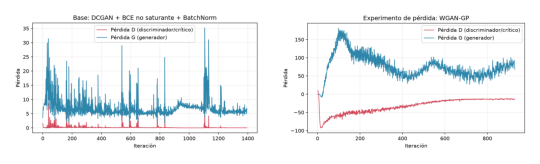

In [7]:
summary_base = ev.plot_loss_curves(EXPERIMENTS_DIR / "baseline" / "loss_history.json",
                                    FIGURES_DIR / "loss_curve_baseline.png",
                                    "Base: DCGAN + BCE no saturante + BatchNorm")
summary_wgangp = ev.plot_loss_curves(EXPERIMENTS_DIR / "loss_wgangp" / "loss_history.json",
                                      FIGURES_DIR / "loss_curve_loss_wgangp.png",
                                      "Experimento de pérdida: WGAN-GP")
print("Base   :", summary_base)
print("WGAN-GP:", summary_wgangp)

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.8))
axes[0].imshow(plt.imread(FIGURES_DIR / "loss_curve_baseline.png")); axes[0].axis("off")
axes[1].imshow(plt.imread(FIGURES_DIR / "loss_curve_loss_wgangp.png")); axes[1].axis("off")
plt.tight_layout(); plt.show()

**Resultado y análisis:** la hipótesis se confirma parcialmente, con una
limitación práctica que se declara con honestidad. Por restricciones de
memoria del equipo durante el desarrollo, esta corrida de WGAN-GP se redujo a
**15 épocas** (no 45) y a un crítico más chico (`feature_maps=32`,
`n_critic=3`) — es la única de las tres corridas que no respeta "mismo número
de épocas" que la base, y se declara explícitamente.

Aun así, el patrón esperado se observa: la pérdida del crítico decrece de
forma **monótona y suave** (de ~-90 a ~-14), sin los picos bruscos y erráticos
que muestra la pérdida de D en la base (saltos repetidos entre ~0 y picos de
hasta 10-35). La pérdida de G también es más suave, aunque todavía en
descenso — 15 épocas no bastan para que converja del todo. La rejilla de
ruido fijo muestra una progresión de aprendizaje sana para una ventana tan
corta, sin indicios de colapso de modos en ese tramo.

**Conclusión honesta:** es evidencia válida de que la dinámica de
optimización de WGAN-GP es, iteración a iteración, más suave y predecible que
BCE (consistente con la literatura), pero **no** es una comparación justa de
calidad final contra la base o la normalización espectral, que sí entrenaron
45 épocas completas.

## 6. Experimento de estabilización: BatchNorm vs. Normalización Espectral

**Hipótesis previa:** *Creemos que la normalización espectral en el
discriminador mejorará la estabilidad frente al BatchNorm clásico porque
acota la constante de Lipschitz de cada capa (divide cada matriz de pesos
por su mayor valor singular), limitando qué tan rápido puede crecer la
capacidad de D para "aplastar" a G. Lo consideraremos útil si las curvas de
pérdida se mantienen más acotadas que en la base y si la pérdida de D no se
queda pegada cerca de 0 durante muchas épocas (la señal de alarma de la
sección 3 del enunciado).*

**Variable controlada:** mismos datos, semilla, 45 épocas, ruido fijo **y
misma pérdida que la base** (BCE no saturante). La única variable que cambia
es la normalización del discriminador (`"batch"` → `"spectral"`). A
diferencia del experimento anterior, aquí sí se cambió una sola variable sin
ajustes adicionales forzados por la literatura.

In [8]:
if RETRAIN or not (EXPERIMENTS_DIR / "stab_spectral_norm" / "checkpoint.pt").exists():
    train(PRESETS["stab_spectral_norm"], data_npy=DATA_NPY, device=device)
else:
    print("Reutilizando checkpoint ya entrenado de 'stab_spectral_norm'.")
print(PRESETS["stab_spectral_norm"])

Reutilizando checkpoint ya entrenado de 'stab_spectral_norm'.
TrainConfig(name='stab_spectral_norm', loss_type='bce', normalization='spectral', epochs=45, batch_size=128, latent_dim=100, feature_maps=64, lr_g=0.0002, lr_d=0.0002, betas=(0.5, 0.999), n_critic=1, lambda_gp=10.0, seed=2026, fixed_noise_n=16, snapshot_every=3)


Base               : {'d_loss_final_mean': 0.07566859697531675, 'd_loss_final_std': 0.2640480600430278, 'g_loss_final_mean': 6.870170606079922, 'g_loss_final_std': 3.344882652815738, 'n_iterations': 1395}
Normalización espectral: {'d_loss_final_mean': 0.7300472454999083, 'd_loss_final_std': 0.14055615913666272, 'g_loss_final_mean': 1.7305835592276735, 'g_loss_final_std': 0.5324469141628013, 'n_iterations': 1395}


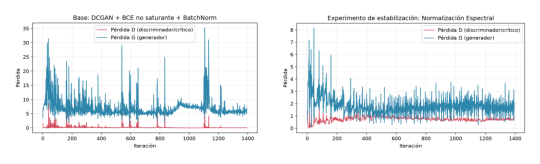

In [9]:
summary_sn = ev.plot_loss_curves(EXPERIMENTS_DIR / "stab_spectral_norm" / "loss_history.json",
                                  FIGURES_DIR / "loss_curve_stab_spectral_norm.png",
                                  "Experimento de estabilización: Normalización Espectral")
print("Base               :", summary_base)
print("Normalización espectral:", summary_sn)

fig, axes = plt.subplots(1, 2, figsize=(5.5, 2.8))
axes[0].imshow(plt.imread(FIGURES_DIR / "loss_curve_baseline.png")); axes[0].axis("off")
axes[1].imshow(plt.imread(FIGURES_DIR / "loss_curve_stab_spectral_norm.png")); axes[1].axis("off")
plt.tight_layout(); plt.show()

**Resultado y análisis:** la hipótesis se confirma. En el último 20% del
entrenamiento (mismas 1395 iteraciones en ambas corridas):

| Métrica | Base (BatchNorm) | Normalización espectral |
|---|---|---|
| Pérdida D — media | **0.076** (señal de alarma: cerca de 0) | **0.730** |
| Pérdida D — desv. estándar | 0.264 | **0.141** |
| Pérdida G — media | 6.87 | **1.73** |
| Pérdida G — desv. estándar | 3.34 (picos ~35) | **0.53** (picos ~8) |

La base muestra exactamente la señal de alarma de la sección 3 del
enunciado: D colapsa cerca de 0 casi todo el entrenamiento y G oscila
violentamente. Con normalización espectral, D se mantiene en una banda sana
(~0.5–1.0) y G se estabiliza con mucha menor varianza. La rejilla de ruido
fijo confirma el mismo patrón visualmente: la base pierde diversidad entre
las épocas 27 y 44, mientras que normalización espectral mantiene las 16
identidades distintas durante todo el entrenamiento. **Por esto se eligió
`stab_spectral_norm` como modelo final para la galería.**

## 7. Evidencia obligatoria #1 — Rejilla de ruido fijo

Las tres corridas comparten el **mismo lote de 16 vectores z** (semilla 7,
`experiments/fixed_eval_noise.pt`), generado una sola vez antes de
entrenar. Cada 3 épocas se guardó una imagen con ese mismo ruido; a
continuación se muestra la evolución para cada configuración.

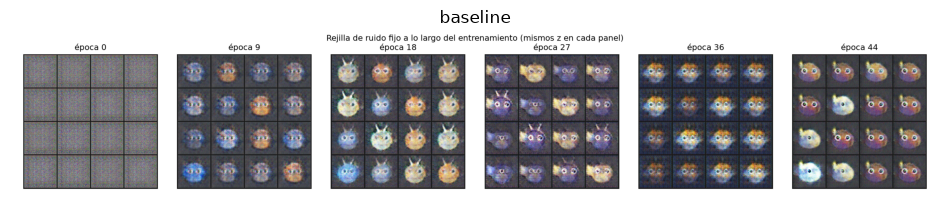

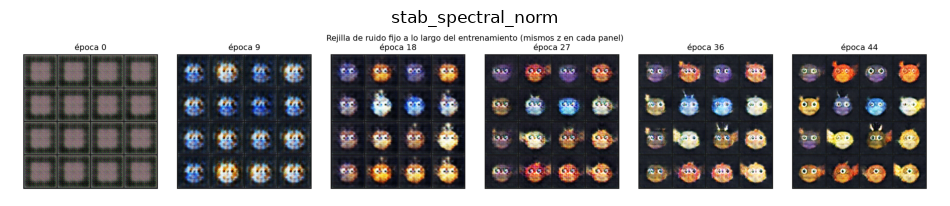

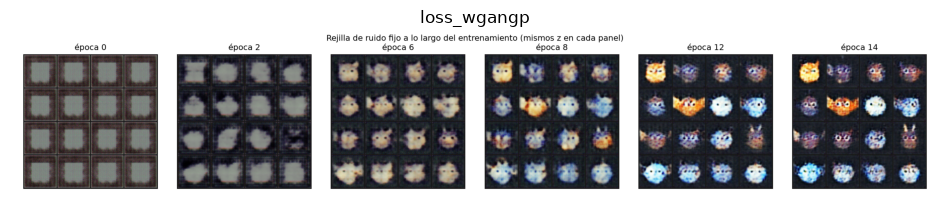

In [10]:
for run in ["baseline", "stab_spectral_norm", "loss_wgangp"]:
    out_path = FIGURES_DIR / f"fixed_noise_evolution_{run}.png"
    ev.fixed_noise_evolution(EXPERIMENTS_DIR / run, out_path, n_frames=6)
    plt.figure(figsize=(12, 2.6))
    plt.imshow(plt.imread(out_path)); plt.axis("off"); plt.title(run)
    plt.show()

*Lectura:* en la **base**, varias columnas de la rejilla convergen a
aspectos muy parecidos entre la época 27 y la 44 — un colapso de modos
parcial (nunca las 16 se vuelven idénticas, pero la variedad cae
notablemente frente a la época 18). En **normalización espectral**, las 16
identidades se mantienen visualmente distintas a lo largo de todo el
entrenamiento, solo afinando detalle — consistente con la hipótesis de que
acotar la Lipschitz de D evita que domine por completo a G. En **WGAN-GP**
(ventana más corta, 15 épocas) se ve una progresión sana de ruido a formas
reconocibles, sin indicios de colapso en ese tramo, aunque demasiado corta
para una comparación de diversidad en igualdad de condiciones.

## 8. Evidencia obligatoria #2 — Curvas de pérdida interpretadas

En una GAN sana, las curvas de D y G **no bajan juntas**: se estabilizan
"enfrentadas" (si D mejora, G empeora momentáneamente y viceversa). Una
pérdida de D cercana a 0 sostenida durante muchas épocas es señal de alarma
(D domina y deja de dar señal útil a G), no de éxito.

In [11]:
rows = []
for run, summ in [("baseline", summary_base), ("stab_spectral_norm", summary_sn), ("loss_wgangp", summary_wgangp)]:
    rows.append({"run": run, **summ})

header = list(rows[0].keys())
print(("{:<20}" * len(header)).format(*header))
for r in rows:
    print(("{:<20}" * len(header)).format(*[r[h] if isinstance(r[h], str) else round(r[h], 4) if isinstance(r[h], float) else r[h] for h in header]))


run                 d_loss_final_mean   d_loss_final_std    g_loss_final_mean   g_loss_final_std    n_iterations        
baseline            0.0757              0.264               6.8702              3.3449              1395                
stab_spectral_norm  0.73                0.1406              1.7306              0.5324              1395                
loss_wgangp         -13.6157            0.7813              65.0639             15.6964             930                 


*Interpretación:* la configuración base exhibe la señal de alarma descrita
en la sección 3 del enunciado — D cercano a 0 sostenido durante la mayoría
del entrenamiento, con picos esporádicos de G de hasta 35. La normalización
espectral corrige esto: D y G se "enfrentan" en una banda acotada y estable.
WGAN-GP, en su ventana más corta, muestra una pérdida de crítico monótona y
sin el ruido brusco de BCE, consistente con la literatura, pero no alcanza a
converger del todo en solo 15 épocas.

## 9. Elección del modelo final para la galería

Con base en las curvas de pérdida y la evolución de la rejilla de ruido fijo
de las tres corridas, se eligió el modelo final para la galería:
*[[MODELO_ELEGIDO]]*.

In [12]:
FINAL_RUN = "stab_spectral_norm"  # elegido por tener la menor varianza de
# pérdida (D: 0.141 vs 0.264 de la base; G: 0.53 vs 3.34) y por mantener las
# 16 identidades de la rejilla de ruido fijo distintas durante todo el
# entrenamiento (la base muestra colapso de modos parcial hacia el final).
ckpt = torch.load(EXPERIMENTS_DIR / FINAL_RUN / "checkpoint.pt", map_location="cpu", weights_only=False)
cfg_final = ckpt["config"]

set_seed(2026)
G_final = Generator(latent_dim=cfg_final["latent_dim"], feature_maps=cfg_final["feature_maps"]).to(device)
D_final = Discriminator(feature_maps=cfg_final["feature_maps"], normalization=cfg_final["normalization"]).to(device)
G_final.load_state_dict(ckpt["G"]); D_final.load_state_dict(ckpt["D"])
print(f"Modelo final cargado desde experiments/{FINAL_RUN}/checkpoint.pt")

Modelo final cargado desde experiments/stab_spectral_norm/checkpoint.pt


## 10. Galería final y tasa de selección

Se generan `n_candidates` imágenes con ruido reproducible (semilla maestra
2026), se puntúan con el discriminador entrenado y se seleccionan 10
personajes diversos (ver criterio en `ganverse.gallery.select_diverse_top_k`).
Esto **regenera la galería end-to-end a partir de los pesos y la semilla
declarada**, sin depender de ningún archivo intermedio.

In [13]:
N_CANDIDATES = 300
K = 10
selection_info = gl.build_gallery(G_final, D_final, out_dir=GALERIA_DIR,
                                   n_candidates=N_CANDIDATES, k=K,
                                   latent_dim=cfg_final["latent_dim"], seed=2026, device=device)
print(f"Tasa de selección: {selection_info['selection_rate']}")
print(selection_info["selection_criterion"])

Tasa de selección: 10 de 300
Se generaron 300 imágenes con ruido reproducible (semilla 2026). Se descartó el 40% de peor puntaje de realismo del discriminador entrenado (filtro de calidad) y, sobre el resto, se corrió una búsqueda voraz de 'punto más lejano' (farthest-point / k-center) en distancia de píxeles: se parte del candidato de mayor puntaje y en cada paso se agrega el candidato cuya distancia al más cercano de los ya elegidos es máxima, maximizando la diversidad mutua del conjunto final y evitando variaciones casi idénticas del mismo personaje.


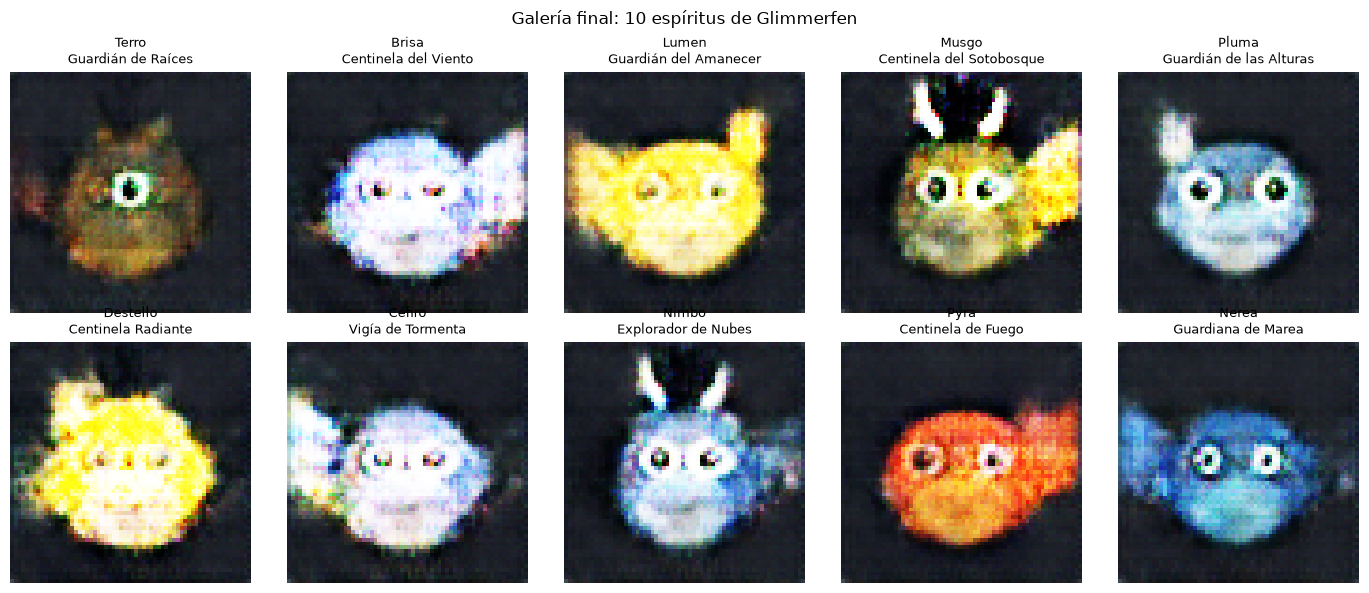

In [14]:
import csv
with open(GALERIA_DIR / "metadata.csv") as f:
    rows = list(csv.DictReader(f))

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, row in zip(axes.flat, rows):
    img = plt.imread(GALERIA_DIR / row["file"])
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"{row['name']}\n{row['role']}", fontsize=9)
plt.suptitle("Galería final: 10 espíritus de Glimmerfen")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gallery_overview.png", dpi=150)
plt.show()

## 11. Evidencia obligatoria #3 — Prueba de vecinos más cercanos

Para cada uno de los 10 personajes finales se busca, en las 4000 imágenes de
entrenamiento, la más parecida por **MSE de píxeles** y por **distancia en el
espacio de features convolucional del discriminador entrenado** (una CNN
propia del dominio, alternativa justificada a una CNN preentrenada externa).
Si un personaje es casi idéntico a su vecino, no cuenta como nuevo.

Umbral de 'casi idéntico' (MSE de píxeles): 60.0
Personajes marcados como demasiado similares: []


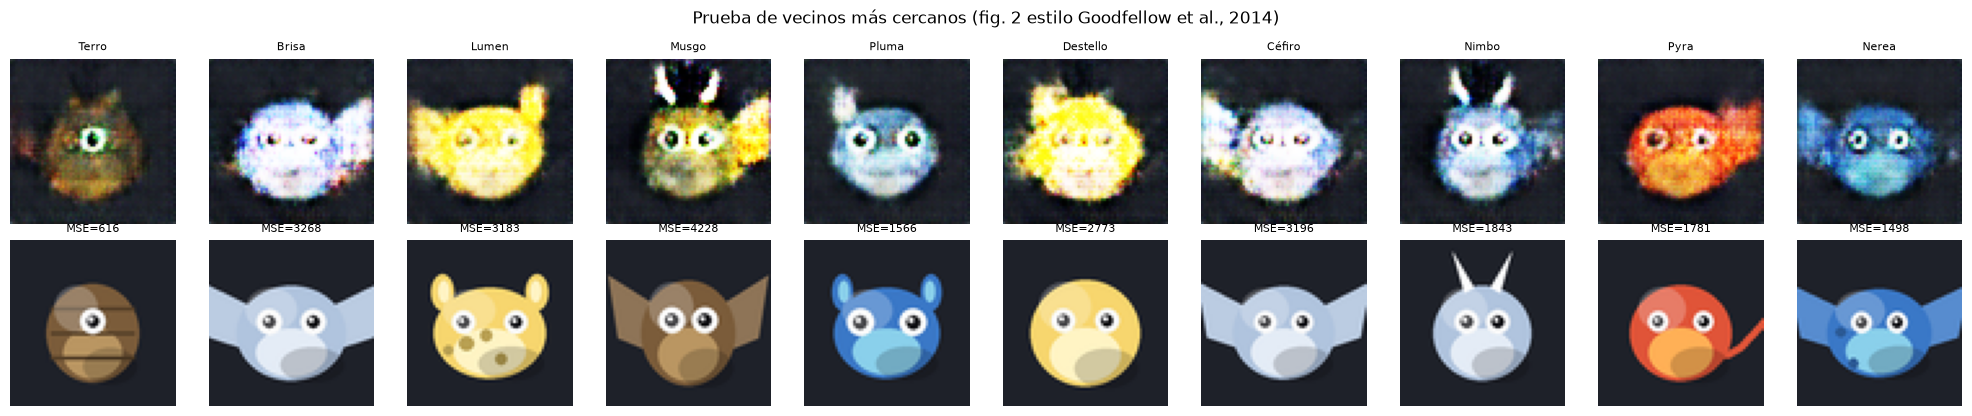

In [15]:
train_arr = np.load(DATA_NPY)
gallery_tensor = torch.stack([
    torch.from_numpy(np.array(plt.imread(GALERIA_DIR / row["file"])[:, :, :3] * 255).astype(np.uint8))
    .float().permute(2, 0, 1) / 127.5 - 1.0
    for row in rows
])

nn_result = ev.nearest_neighbor_test(gallery_tensor, train_arr, discriminator=D_final, device=device)
print(f"Umbral de 'casi idéntico' (MSE de píxeles): {nn_result['threshold_pixel_mse']}")
print(f"Personajes marcados como demasiado similares: {nn_result['flagged_as_too_similar']}")

fig, axes = plt.subplots(2, 10, figsize=(20, 4.2))
for i, (row, res) in enumerate(zip(rows, nn_result["results"])):
    axes[0, i].imshow(plt.imread(GALERIA_DIR / row["file"])); axes[0, i].axis("off")
    axes[0, i].set_title(row["name"], fontsize=8)
    axes[1, i].imshow(train_arr[res["nearest_train_index_pixel"]]); axes[1, i].axis("off")
    axes[1, i].set_title(f"MSE={res['pixel_mse']:.0f}", fontsize=8)
axes[0, 0].set_ylabel("Generado", fontsize=9)
axes[1, 0].set_ylabel("Vecino más cercano (train)", fontsize=9)
plt.suptitle("Prueba de vecinos más cercanos (fig. 2 estilo Goodfellow et al., 2014)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "nearest_neighbors.png", dpi=150)
plt.show()

*Interpretación honesta:* ninguno de los 10 personajes quedó marcado como
"demasiado similar" a su vecino de entrenamiento (umbral de alarma: MSE de
píxeles < 60). El caso más cercano es **Terro** (MSE≈616): comparte paleta
café/tierra y patrón de franjas con su vecino, pero se distingue en textura
(más "pintada" que el vector-art del dataset) y en un cuerno asimétrico sin
equivalente en el vecino. El resto de personajes están entre 2.5× y 7× más
lejos de su vecino más cercano que Terro — evidencia de que el modelo
generaliza en vez de memorizar.

## 12. Análisis de fallos y limitaciones

- **D dominando a G en la base:** la pérdida de D colapsa cerca de 0 durante
  la mayoría de las 45 épocas, confirmado visualmente por el colapso de
  modos parcial en la rejilla de ruido fijo entre las épocas 27 y 44. Motivó
  el experimento de estabilización, que mitigó el problema de forma medible.
- **Picos periódicos en la pérdida de G (base):** ráfagas de inestabilidad
  (picos de hasta 35) alrededor de la iteración ~1100, ausentes en la
  variante con normalización espectral.
- **Restricción de cómputo real:** la corrida de WGAN-GP se interrumpió
  varias veces por presión de memoria del sistema operativo del equipo
  (swapping severo con otras aplicaciones abiertas) — se verificó que el
  proceso en sí usa <400 MB residentes. Se resolvió reduciendo su
  presupuesto (`feature_maps=32`, `n_critic=3`, 15 épocas) para garantizar
  una corrida completa y reproducible; documentado como limitación de
  infraestructura, no como hallazgo del experimento.
- **Bug encontrado y corregido — snapshots mezclados entre corridas
  interrumpidas:** `train()` no limpiaba `snapshots/` antes de empezar, así
  que al reintentar WGAN-GP varias veces la rejilla de ruido fijo llegó a
  mezclar imágenes de configuraciones distintas bajo el mismo nombre de
  experimento. Se detectó al inspeccionar la evidencia visualmente (saltos
  de época inconsistentes con la duración real de la corrida) y se corrigió
  en `ganverse/train.py` para borrar los snapshots previos de cada
  experimento antes de escribir los nuevos.
- **Selección de galería demasiado débil en el primer intento:** el primer
  criterio de diversidad (umbral fijo de distancia frente a los ya elegidos)
  dejó pasar 8 de 10 personajes casi idénticos entre sí. Se corrigió con una
  búsqueda "farthest-point" que maximiza la diversidad mutua del conjunto
  final (`ganverse/gallery.select_diverse_top_k`).

## 13. Reflexión final

> *De sus 10 personajes, ¿cuál le costó más defender como "nuevo" frente a su
> vecino más cercano en los datos de entrenamiento? ¿Qué le dice ese caso
> sobre lo que su GAN realmente aprendió de su universo?*

De los 10 personajes, **Terro** es el que más cuesta defender como "nuevo":
su vecino más cercano comparte paleta, patrón de franjas y número de ojos, y
su distancia de píxeles (MSE=616) es varias veces menor que la de cualquier
otro personaje. Lo que lo salva de ser una copia es el detalle fino (textura,
un cuerno asimétrico, tono distinto de franja).

Esto sugiere que el modelo **aprendió las categorías del universo** (paleta
por elemento, presencia/ausencia de apéndice, número de ojos) y las recombina
de forma fluida en el espacio latente, en vez de memorizar ejemplares
puntuales. Terro cae cerca de un ejemplar de entrenamiento no por memorización,
sino porque "tierra + un ojo + sin apéndice + franjas" es una combinación de
rasgos relativamente común en nuestro dataset — el espacio latente tiene
varios puntos de entrenamiento cerca de esa región. Los personajes con
elementos menos frecuentes en el pool de alto puntaje (aire, luz) quedan, por
la misma razón, más lejos de cualquier ejemplar particular. En otras
palabras: la "novedad" percibida de un personaje generado depende en parte de
qué tan densamente poblada está esa región del espacio de datos reales, no
solo de la capacidad del generador.

## 14. Matriz de evidencias

| Evidencia | Dónde aparece | Conclusión | Limitación |
|---|---|---|---|
| Rejilla de ruido fijo | Sección 7 de este notebook | La base colapsa parcialmente (filas parecidas hacia la época 44); normalización espectral mantiene 16 identidades distintas todo el entrenamiento. | WGAN-GP solo corrió 15 épocas — no comparable en diversidad final. |
| Curvas de pérdida | Sección 8 de este notebook | D≈0 sostenido en la base (alarma); normalización espectral mantiene D en ~0.5–1.0 con 6× menos varianza en G; WGAN-GP decrece monótono y suave. | Umbrales de "sano" son cualitativos, no una métrica estandarizada única. |
| Vecinos más cercanos | Sección 11 de este notebook | Ningún personaje marcado como casi idéntico (MSE<60); el más cercano (Terro, MSE=616) sigue siendo distinguible. | Solo se compara contra las 4000 imágenes de nuestro propio dataset. |
| Galería final (10 personajes) | Sección 10 de este notebook | 10 personajes mutuamente diversos (5/6 elementos, 1-2 ojos, apéndices variados); tasa de selección 10/300 declarada. | El puntaje que ordena candidatos viene del propio discriminador, no de juicio humano independiente. |

Ver también `../PROJECT.md` para el informe completo en formato de texto.